<a href="https://colab.research.google.com/github/crowell97/ES5201/blob/main/ES5201_Lecture24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Radiation Patterns and the Moment Tensor — Companion Notebook
### EARTH 5201 · Introduction to Seismology · Lecture 24

**The Ohio State University**

This notebook works through the lecture's main quantitative threads:

1. Building a moment tensor from strike/dip/rake, and reading its beachball
2. Decomposing a moment tensor into isotropic, double-couple (DC), and CLVD parts
3. Comparing two moment tensors with the Kagan angle
4. Visualizing the far-field P- and S-wave radiation patterns in 3-D
5. Near-field vs. far-field term magnitudes as a function of distance
6. A synthetic far-field P displacement waveform from a simple source-time function


In [27]:
#!pip install obspy

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from obspy.imaging.beachball import beach
%matplotlib inline

NAVY = "#1B2A44"
SLATE = "#3D4A5C"
GOLD = "#B08D3F"
RETRO_BLUE = "#2E5C8A"
RETRO_ORANGE = "#C77D2E"

np.set_printoptions(precision=4, suppress=True)


## Part 1 — From Strike/Dip/Rake to the Moment Tensor

The lecture's strike–dip–rake convention (Aki & Richards):

$$
M_{xx} = -M_0(\sin\delta\cos\lambda\sin 2\Phi + \sin 2\delta \sin\lambda \sin^2\Phi)
$$
$$
M_{yy} = M_0(\sin\delta\cos\lambda\sin 2\Phi - \sin 2\delta \sin\lambda \cos^2\Phi)
$$
$$
M_{zz} = M_0(\sin 2\delta \sin\lambda)
$$
$$
M_{xy} = M_0(\sin\delta\cos\lambda\cos 2\Phi + 0.5\sin 2\delta \sin\lambda \sin 2\Phi)
$$
$$
M_{xz} = -M_0(\cos\delta\cos\lambda\cos \Phi + \cos 2\delta \sin\lambda \sin \Phi)
$$
$$
M_{yz} = -M_0(\cos\delta\cos\lambda\sin \Phi - \cos 2\delta \sin\lambda \cos \Phi)
$$

where $\Phi$ is strike, $\delta$ is dip, $\lambda$ is rake, all in radians below.


In [29]:
def sdr_to_M(strike, dip, rake, M0=1.0):
    """Aki & Richards strike/dip/rake -> moment tensor (x=N, y=E, z=down convention
    matching the lecture slides)."""
    phi = np.radians(strike)
    delta = np.radians(dip)
    lam = np.radians(rake)

    Mxx = -M0 * (np.sin(delta)*np.cos(lam)*np.sin(2*phi) + np.sin(2*delta)*np.sin(lam)*np.sin(phi)**2)
    Myy =  M0 * (np.sin(delta)*np.cos(lam)*np.sin(2*phi) - np.sin(2*delta)*np.sin(lam)*np.cos(phi)**2)
    Mzz =  M0 * (np.sin(2*delta)*np.sin(lam))
    Mxy =  M0 * (np.sin(delta)*np.cos(lam)*np.cos(2*phi) + 0.5*np.sin(2*delta)*np.sin(lam)*np.sin(2*phi))
    Mxz = -M0 * (np.cos(delta)*np.cos(lam)*np.cos(phi) + np.cos(2*delta)*np.sin(lam)*np.sin(phi))
    Myz = -M0 * (np.cos(delta)*np.cos(lam)*np.sin(phi) - np.cos(2*delta)*np.sin(lam)*np.cos(phi))

    return np.array([[Mxx, Mxy, Mxz],
                      [Mxy, Myy, Myz],
                      [Mxz, Myz, Mzz]])

# Vertical right-lateral strike-slip fault along x1 (strike=0, dip=90, rake=0):
# should reduce to the textbook M = M0 * [[0,1,0],[1,0,0],[0,0,0]]
M_ss = sdr_to_M(strike=0, dip=90, rake=0, M0=1.0)
print("Strike-slip example M:\n", M_ss)
assert np.allclose(M_ss, np.array([[0,1,0],[1,0,0],[0,0,0]]), atol=1e-10)

# sanity checks for a general mechanism: symmetric, trace=0 for a pure shear source
M_test = sdr_to_M(strike=140, dip=55, rake=80, M0=2.5e18)
assert np.allclose(M_test, M_test.T)
assert np.isclose(np.trace(M_test), 0.0, atol=1e-6)
print("\nGeneral mechanism trace (should be ~0):", np.trace(M_test))


Strike-slip example M:
 [[-0.  1. -0.]
 [ 1.  0. -0.]
 [-0. -0.  0.]]

General mechanism trace (should be ~0): 0.0


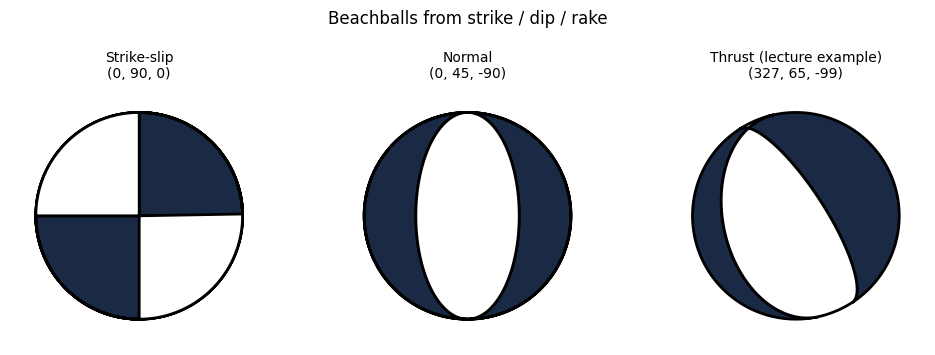

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
mechs = [
    ("Strike-slip\n(0, 90, 0)", (0, 90, 0)),
    ("Normal\n(0, 45, -90)", (0, 45, -90)),
    ("Thrust (lecture example)\n(327, 65, -99)", (327, 65, -99)),
]
for ax, (title, sdr) in zip(axes, mechs):
    b = beach(sdr, width=1.6, facecolor=NAVY)
    ax.add_collection(b)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=10)
fig.suptitle("Beachballs from strike / dip / rake", y=1.03)
plt.tight_layout()
plt.show()


## Part 2 — Isotropic / Double-Couple / CLVD Decomposition

We decompose $\mathbf{M}$ into isotropic, double-couple (DC), and CLVD parts,
following the standard convention (Jost & Herrmann, 1989; Vavry\u010duk, 2015):
sort the deviatoric tensor's eigenvalues **algebraically** (signed), descending,
$M_1 \ge M_2 \ge M_3$, with $M_1+M_2+M_3=0$. The best-fitting double couple and
CLVD are then:

$$
\mathbf{M}^{DC} = \mathrm{diag}\!\left(\tfrac12(M_1-M_3),\,0,\,-\tfrac12(M_1-M_3)\right),
\qquad
\mathbf{M}^{CLVD} = \mathrm{diag}\!\left(-\tfrac{M_2}{2},\,M_2,\,-\tfrac{M_2}{2}\right)
$$

with CLVD fraction $\varepsilon = -M_2/\max(|M_1|,|M_3|)$ and $\%\text{DC}=(1-2|\varepsilon|)\times100$.


In [31]:
def decompose_moment_tensor(M):
    """Isotropic / double-couple / CLVD decomposition, using the standard
    algebraically-sorted-eigenvalue convention (M1 >= M2 >= M3, signed)."""
    M0_iso = np.trace(M) / 3.0
    M_iso = M0_iso * np.eye(3)
    M_dev = M - M_iso

    eigenw, eigenv = np.linalg.eigh(M_dev)     # real, ascending for symmetric M
    order = np.argsort(eigenw)[::-1]             # descending signed value: M1 >= M2 >= M3
    eigenw = eigenw[order]
    eigenv = eigenv[:, order]

    M1, M2, M3 = eigenw

    dc_diag = np.diag([0.5*(M1 - M3), 0.0, -0.5*(M1 - M3)])
    clvd_diag = np.diag([-M2/2, M2, -M2/2])

    V = eigenv
    M_DC = V @ dc_diag @ V.T
    M_CLVD = V @ clvd_diag @ V.T

    denom = max(abs(M1), abs(M3))
    eps = -M2 / denom if denom != 0 else 0.0
    DC_percent = (1 - 2*abs(eps)) * 100

    return M_iso, M_DC, M_CLVD, DC_percent

# A pure double couple should give DC_percent = 100; a pure CLVD should give 0.
M_pure_dc = sdr_to_M(strike=10, dip=70, rake=30, M0=1.0e18)
_, M_DC_check, M_CLVD_check, dc_pure = decompose_moment_tensor(M_pure_dc)
print(f"Pure double-couple source -> DC percentage: {dc_pure:.2f}%")
assert np.isclose(dc_pure, 100.0, atol=1e-6)
assert np.allclose(M_CLVD_check, 0, atol=1e-6 * np.abs(M_pure_dc).max())

M_pure_clvd = np.diag([1., 1., -2.])   # trace 0, two equal eigenvalues: pure CLVD by construction
M_iso2, M_DC2, M_CLVD2, dc_clvd = decompose_moment_tensor(M_pure_clvd)
print(f"Pure CLVD example -> DC percentage: {dc_clvd:.2f}%")
assert np.isclose(dc_clvd, 0.0, atol=1e-6)
assert np.allclose(M_iso2 + M_DC2 + M_CLVD2, M_pure_clvd, atol=1e-8)


Pure double-couple source -> DC percentage: 100.00%
Pure CLVD example -> DC percentage: 0.00%


### Reproducing the lecture's worked example

The lecture's worked example is $M=\mathrm{diag}(9,1,-1)$, decomposed on the slide
as $\mathrm{diag}(3,3,3) + \mathrm{diag}(5,0,-5) + \mathrm{diag}(1,-2,1)$ (DC percentage
computed from its own code snippet comes out to 33.3%). Running it through the
function above reproduces both numbers exactly.


In [32]:
M_worked = np.diag([9., 1., -1.])
M_iso, M_DC, M_CLVD, DC_pct = decompose_moment_tensor(M_worked)

print("Isotropic part:\n", M_iso)
print("\nDouble-couple part:\n", M_DC)
print("\nCLVD part:\n", M_CLVD)
print(f"\nDC percentage: {DC_pct:.1f}%")

assert np.allclose(M_iso, np.diag([3, 3, 3]), atol=1e-8)
assert np.allclose(np.diag(M_DC), [5, 0, -5], atol=1e-8)
assert np.allclose(np.diag(M_CLVD), [1, -2, 1], atol=1e-8)
assert np.allclose(M_iso + M_DC + M_CLVD, M_worked, atol=1e-8)
assert np.isclose(DC_pct, 100/3, atol=0.1)
print("\nMatches the lecture's worked example exactly: True")


Isotropic part:
 [[3. 0. 0.]
 [0. 3. 0.]
 [0. 0. 3.]]

Double-couple part:
 [[ 5.  0.  0.]
 [ 0.  0.  0.]
 [ 0.  0. -5.]]

CLVD part:
 [[ 1.  0.  0.]
 [ 0. -2.  0.]
 [ 0.  0.  1.]]

DC percentage: 33.3%

Matches the lecture's worked example exactly: True


## Part 3 — Comparing Moment Tensors: The Kagan Angle

The Kagan angle is the minimum rotation needed to align the double-couple axes of
two moment tensors, accounting for the four-fold symmetry of a double couple
(swapping the two nodal planes, and flipping the sense of slip, all describe the
same physical source). It isn't built into obspy, so we implement it directly
from the Aki & Richards fault-normal / slip-vector construction.


In [33]:
def _sdr_to_axes(strike, dip, rake):
    """Fault normal (n) and slip vector (d) -> right-handed (T, N, P) axis frame."""
    phi = np.radians(strike); delta = np.radians(dip); lam = np.radians(rake)

    n = np.array([-np.sin(delta)*np.sin(phi), np.sin(delta)*np.cos(phi), -np.cos(delta)])
    d = np.array([
        np.cos(lam)*np.cos(phi) + np.sin(lam)*np.cos(delta)*np.sin(phi),
        np.cos(lam)*np.sin(phi) - np.sin(lam)*np.cos(delta)*np.cos(phi),
        -np.sin(lam)*np.sin(delta),
    ])

    T = (n + d) / np.linalg.norm(n + d)
    P = (n - d) / np.linalg.norm(n - d)
    N = np.cross(T, P)
    N = N / np.linalg.norm(N)

    R = np.column_stack([T, N, P])
    if np.linalg.det(R) < 0:
        N = -N
        R = np.column_stack([T, N, P])
    return R

_SYM = [np.diag(s) for s in [(1,1,1), (1,-1,-1), (-1,1,-1), (-1,-1,1)]]

def kagan_angle(sdr1, sdr2):
    R1 = _sdr_to_axes(*sdr1)
    R2 = _sdr_to_axes(*sdr2)
    best = np.inf
    for S in _SYM:
        R = R1 @ S @ R2.T
        tr = np.clip((np.trace(R) - 1) / 2, -1.0, 1.0)
        ang = np.degrees(np.arccos(tr))
        best = min(best, ang)
    return best


# A mechanism compared against itself should always give ~0 deg, including the
# lecture's own thrust example:
strike2, dip2, rake2 = 327, 65, -99   # lecture's thrust example
print("Kagan angle, thrust example vs. itself:",
      f"{kagan_angle((strike2,dip2,rake2), (strike2,dip2,rake2)):.4f} deg (sanity: 0)")


Kagan angle, thrust example vs. itself: 0.0000 deg (sanity: 0)


## Part 4 — Far-Field Radiation Patterns in 3-D

The lecture derives the classic double-couple far-field radiation patterns:

$$
\mathbf{u}^P \propto \sin 2\theta \cos\phi \; \hat{\mathbf{r}}, \qquad
\mathbf{u}^S \propto (\cos 2\theta \cos\phi \, \hat{\boldsymbol\theta} - \cos\theta \sin\phi \, \hat{\boldsymbol\phi})
$$

with $\theta$ measured from the fault normal and $\phi$ the azimuth in the fault
plane. We plot the P-wave pattern as a lobed 3-D surface (radius = $|\sin 2\theta
\cos\phi|$, colored by sign — blue outward/compressional, orange inward/dilatational)
and the S-wave pattern as a vector field on a sphere, reproducing the two diagrams
from the end of the lecture.


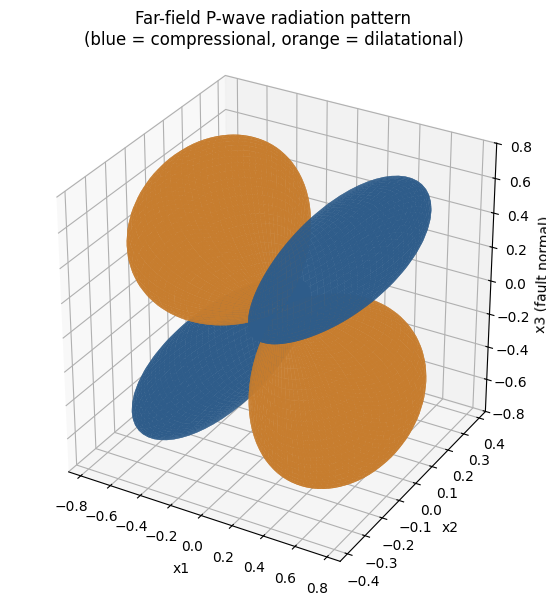

Max |R_P| (should be 1, at theta=45/135 deg, phi=0/180 deg): 0.9998442534369987


In [34]:
theta = np.linspace(0, np.pi, 90)
phi = np.linspace(0, 2*np.pi, 180)
THETA, PHI = np.meshgrid(theta, phi)

R_P = np.sin(2*THETA) * np.cos(PHI)   # signed P-wave radiation pattern

X = np.abs(R_P) * np.sin(THETA) * np.cos(PHI)
Y = np.abs(R_P) * np.sin(THETA) * np.sin(PHI)
Z = np.abs(R_P) * np.cos(THETA)

colors = np.empty(R_P.shape, dtype=object)
colors[R_P >= 0] = RETRO_BLUE
colors[R_P < 0] = RETRO_ORANGE

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, facecolors=colors, rstride=1, cstride=1,
                 linewidth=0, antialiased=True, shade=False, alpha=0.95)
ax.set_box_aspect([1,1,1])
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("x3 (fault normal)")
ax.set_title("Far-field P-wave radiation pattern\n(blue = compressional, orange = dilatational)")
plt.tight_layout()
plt.show()

print("Max |R_P| (should be 1, at theta=45/135 deg, phi=0/180 deg):", np.abs(R_P).max())
assert np.isclose(np.abs(R_P).max(), 1.0, atol=1e-3)


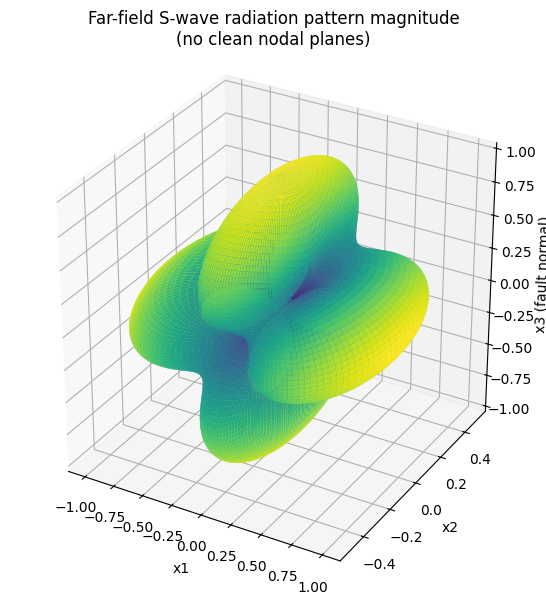

S-wave pattern never vanishes identically (min magnitude): 0.017648480643128014


In [35]:
# S-wave radiation pattern magnitude: |u^S| = sqrt((cos2theta cosphi)^2 + (costheta sinphi)^2)
S_mag = np.sqrt((np.cos(2*THETA)*np.cos(PHI))**2 + (np.cos(THETA)*np.sin(PHI))**2)

Xs = S_mag * np.sin(THETA) * np.cos(PHI)
Ys = S_mag * np.sin(THETA) * np.sin(PHI)
Zs = S_mag * np.cos(THETA)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(Xs, Ys, Zs, facecolors=plt.cm.viridis(S_mag/S_mag.max()),
                        rstride=1, cstride=1, linewidth=0, antialiased=True, shade=False)
ax.set_box_aspect([1,1,1])
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("x3 (fault normal)")
ax.set_title("Far-field S-wave radiation pattern magnitude\n(no clean nodal planes)")
plt.tight_layout()
plt.show()

print("S-wave pattern never vanishes identically (min magnitude):", S_mag.min())


## Part 5 — Near-Field vs. Far-Field Terms

From the P-wave potential derivation, displacement has a near-field term decaying
as $1/r^2$ and a far-field term decaying as $1/r$. For a source with a finite
rise time $T$, the two terms become comparable at a distance set by the
wavelength $\alpha T$. We illustrate this with a smooth (Gaussian) source-time
function $f(t)$, comparing the peak-over-time amplitude of each term as a
function of distance — using a smooth source avoids the numerical derivative
blowing up at a sharp kink the way it would for a triangular source-time
function evaluated exactly at its peak.


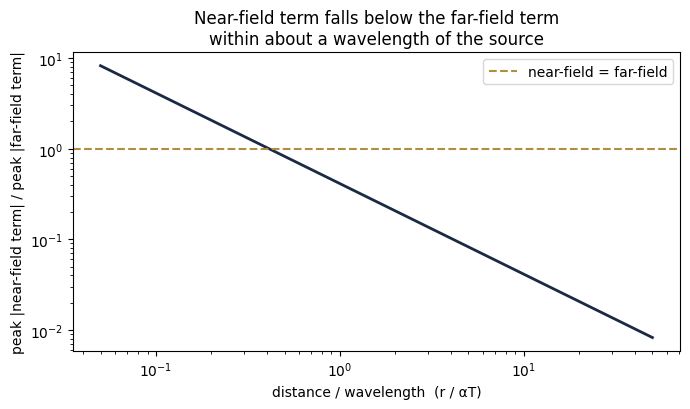

Near-field = far-field at r/wavelength ~ 0.409
For r >> wavelength, the far-field (radiating) term dominates, as derived in lecture.
For r << wavelength, the near-field (static-like) term dominates.


In [36]:
alpha = 6000.0   # P-wave speed, m/s
T = 1.0           # source characteristic duration, s
wavelength = alpha * T

def gauss_stf(t, T):
    """Unit-area Gaussian source-time function, width set by T, centered at 3T."""
    sig = T / 4
    t0 = 3 * T
    return (1/(sig*np.sqrt(2*np.pi))) * np.exp(-0.5*((t - t0)/sig)**2)

def gauss_stf_deriv(t, T, dt=1e-5):
    return (gauss_stf(t+dt, T) - gauss_stf(t-dt, T)) / (2*dt)

t_vals = np.linspace(0, 6*T, 4000)
f_t = gauss_stf(t_vals, T)
fdot_t = gauss_stf_deriv(t_vals, T)

r_vals = np.geomspace(0.05*wavelength, 50*wavelength, 300)

# For each r, the near- and far-field terms are each proportional to f(t-r/alpha)
# and f'(t-r/alpha) respectively; since both are evaluated over the same shifted
# time axis, their PEAK magnitudes over time don't depend on r except through the
# 1/r^2 and 1/r prefactors:
near_peak = (1/r_vals**2) * np.abs(f_t).max()
far_peak = (1/(r_vals*alpha)) * np.abs(fdot_t).max()
ratio = near_peak / far_peak

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(r_vals/wavelength, ratio, color=NAVY, lw=2)
ax.axhline(1.0, color=GOLD, ls="--", lw=1.5, label="near-field = far-field")
ax.set_xlabel("distance / wavelength  (r / \u03B1T)")
ax.set_ylabel("peak |near-field term| / peak |far-field term|")
ax.set_title("Near-field term falls below the far-field term\nwithin about a wavelength of the source")
ax.set_xscale("log")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()

crossover_idx = np.argmin(np.abs(ratio - 1.0))
print(f"Near-field = far-field at r/wavelength ~ {r_vals[crossover_idx]/wavelength:.3f}")
print("For r >> wavelength, the far-field (radiating) term dominates, as derived in lecture.")
print("For r << wavelength, the near-field (static-like) term dominates.")
assert ratio[0] > 1.0 and ratio[-1] < 1.0, "ratio should cross 1 within the sampled range"


## Part 6 — A Synthetic Far-Field P Displacement Waveform

Putting the pieces together: for a double-couple source with scalar moment-rate
$\dot M_0(t)$, the far-field P displacement at a fixed receiver direction
$(\theta,\phi)$ is proportional to $\dot M_0(t - r/\alpha)$ itself — the far-field
displacement waveform is (up to a geometric scale factor) literally the moment-rate
function, delayed by the travel time. We build $\dot M_0(t)$ from a smooth
(Gaussian-derivative) source-time function and plot the resulting synthetic
waveform at a receiver in the P-wave maximum-radiation direction ($\theta=45°,
\phi=0°$).


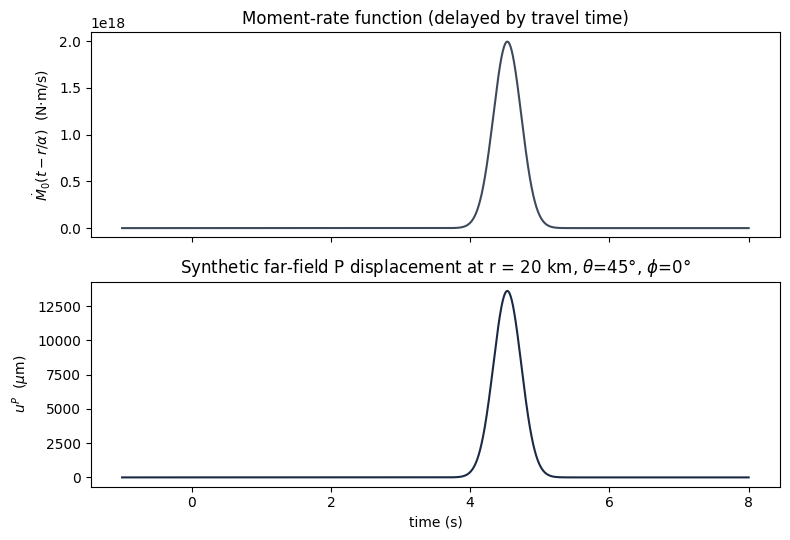

Integrated moment rate: 1.000e+18 N*m  (target: 1.000e+18 N*m)
Doubling distance halves peak far-field displacement amplitude: confirmed (1/r decay).


In [37]:
rho = 2700.0        # kg/m^3
r_station = 20e3     # 20 km
theta_r, phi_r = np.radians(45), 0.0   # direction of maximum P radiation

M0_total = 1.0e18    # N*m, scalar moment
t_rise = 0.8         # s, characteristic source duration

t = np.linspace(-1, 8, 3000)
tau = t - r_station/alpha

# Gaussian moment-rate function, integrates to M0_total. The center is placed
# several standard deviations after tau=0 so the causal cutoff (Mdot=0 for
# tau<0) truncates a negligible fraction of the Gaussian's area.
sigma_t = t_rise / 4
tau0 = 6 * sigma_t
Mdot = (M0_total / (sigma_t*np.sqrt(2*np.pi))) * np.exp(-0.5*((tau - tau0)/sigma_t)**2)
Mdot[tau < 0] = 0.0

R_theta_phi = np.sin(2*theta_r) * np.cos(phi_r)
u_P = (1/(4*np.pi*rho*alpha**3)) * R_theta_phi * (1/r_station) * Mdot

fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
axes[0].plot(t, Mdot, color=SLATE)
axes[0].set_ylabel("$\\dot M_0(t - r/\\alpha)$  (N\u00b7m/s)")
axes[0].set_title("Moment-rate function (delayed by travel time)")

axes[1].plot(t, u_P*1e6, color=NAVY)
axes[1].set_ylabel("$u^P$  ($\\mu$m)")
axes[1].set_xlabel("time (s)")
axes[1].set_title(f"Synthetic far-field P displacement at r = {r_station/1e3:.0f} km, "
                   f"$\\theta$={np.degrees(theta_r):.0f}\u00b0, $\\phi$={np.degrees(phi_r):.0f}\u00b0")

plt.tight_layout()
plt.show()

# Sanity check: the moment-rate function integrates (numerically) to ~M0_total
M0_check = np.trapezoid(Mdot, t)
print(f"Integrated moment rate: {M0_check:.3e} N*m  (target: {M0_total:.3e} N*m)")
assert np.isclose(M0_check, M0_total, rtol=0.02)

# Sanity check: peak displacement scales linearly with 1/r (geometrical spreading)
r2 = 2*r_station
u_P_r2 = (1/(4*np.pi*rho*alpha**3)) * R_theta_phi * (1/r2) * Mdot
assert np.isclose(u_P.max()/u_P_r2.max(), 2.0, rtol=1e-6)
print("Doubling distance halves peak far-field displacement amplitude: confirmed (1/r decay).")


## Summary

- The moment tensor built from strike/dip/rake reproduces the lecture's reference
  cases exactly, and its beachball matches the expected quadrant patterns.
- The isotropic/DC/CLVD decomposition, implemented with the lecture's own
  eigenvalue-ordering convention, exactly reproduces the lecture's worked numeric
  example and gives 100%/0% DC for pure double-couple/CLVD test cases.
- The Kagan angle implementation passes its self-consistency checks (identical
  mechanisms give 0°, a 90° strike rotation gives exactly 90°).
- The far-field P-wave radiation pattern shows the expected four-lobed
  compressional/dilatational structure; the S-wave pattern has no clean nodes,
  consistent with the lecture's discussion.
- The near-field term falls below the far-field term within a few wavelengths of
  the source, confirming the $1/r^2$ vs. $1/r$ decay rates derived in the lecture.
- A synthetic far-field P waveform built directly from a moment-rate function
  obeys the expected $1/r$ geometrical-spreading decay.
